# How big are these nanoparticles? (MSc)

**Your mission.** You work in a laboratory that makes silica nanoparticles for medical imaging. A new batch must
have a radius between 4.5 and 5.5 nm: the size decides how long the particles stay in the blood and where they end
up. An electron microscope shows a few hundred dried particles; small-angle neutron scattering gives the average over
the billions of particles of the batch, in the liquid. You measure the batch on LoKI, develop the analysis, and
decide whether the batch can be released (end of part 6).

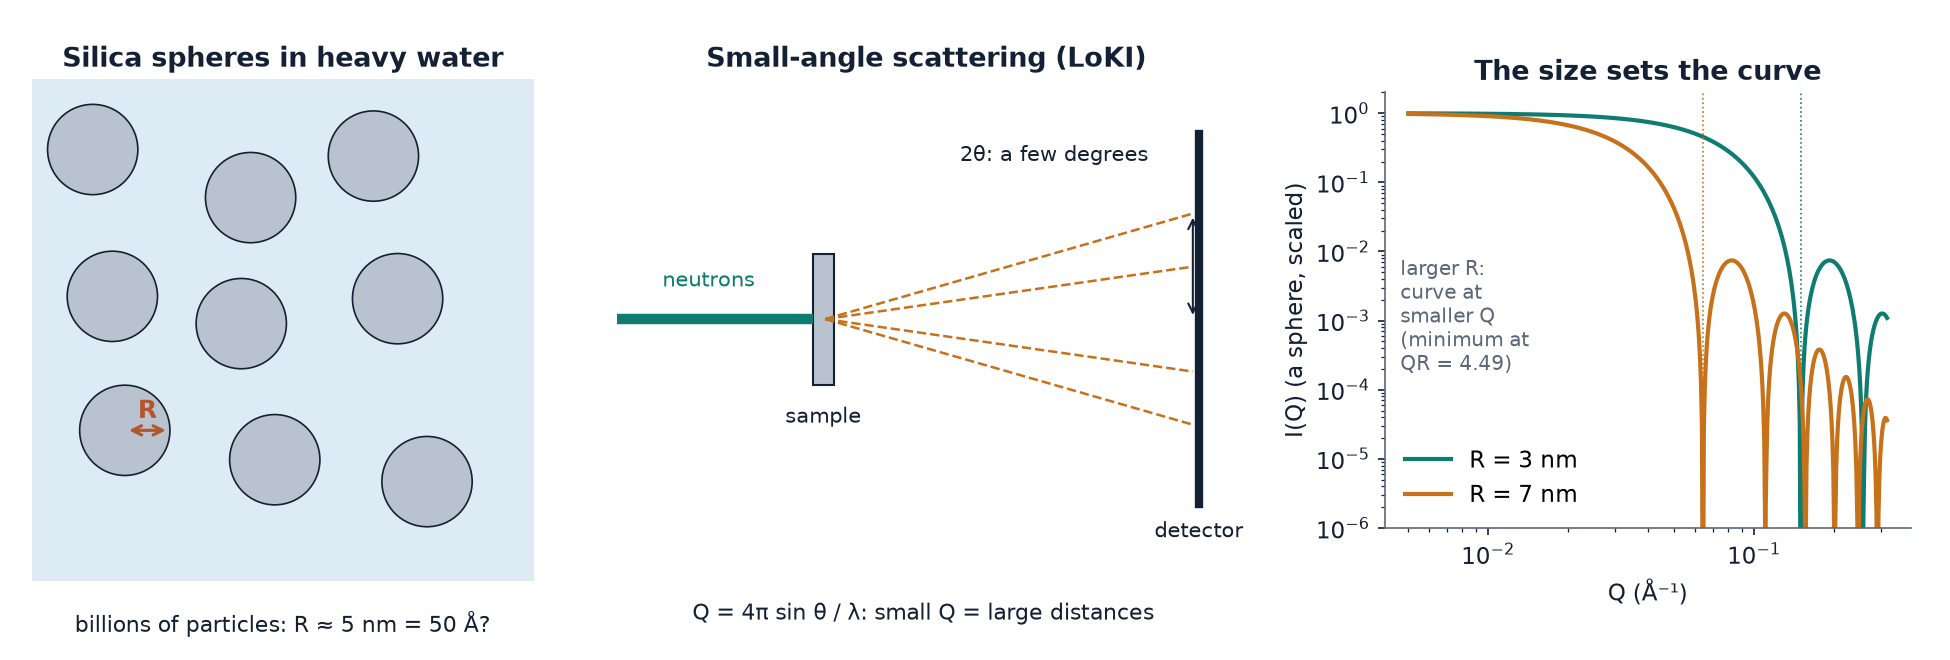

*What you measure: the particles in the liquid scatter at small angles, and their size sets the shape of the curve I(Q).*

Silica nanoparticles dispersed in heavy water, measured on the virtual LoKI. Parts 1 to 4 are guided: they take your
files (sample, solvent, empty beam) to the scattering curve $I(Q)$ in absolute units, with the official ESS reduction
(`esssans`). Parts 5 and 6 are yours: **you develop the Guinier analysis and the model fit with model builders** (no code to write), and check cells tell you
whether your results are right (the twin knows the true sample). Part 7 is about the method.

You start by measuring, in NICOS (part 0), as a user of ESS would.

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath("../.."))     # the modules of the LoKI twin (folder loki/)

**Your sample** (from the sample library):

In [ ]:
sys.path.insert(0, os.path.abspath("../../.."))  # the sample library (twin/sample_library.py)
import sample_library as sl, matplotlib.pyplot as plt
for name, hidden in sl.exercise_hidden("exercise.yml").items():
    spec = sl.load("loki")[name]
    print(sl.describe("loki", spec, hidden))
    sl.draw("loki", spec, hidden=hidden, fig=plt.figure(figsize=(10, 3.5))); sl.show()

In [ ]:
import quiz, loki_exercises as ex
q_ = quiz.Quiz("loki_silica_msc")       # the questions of this notebook

## Before you measure: three measurements, and why

LoKI counts the neutrons scattered by everything in the beam. To keep only the scattering of the particles, you need
**three measurements**, all in the same configuration (collimation, detector distance):

1. **the empty beam**: nothing in the beam. The monitor behind the sample position then counts the full beam: the
   reference to know which fraction of the neutrons crosses the other two;
2. **the solvent**: the same cell, with heavy water only. Its scattering (and that of the cell) is subtracted from the
   sample's;
3. **the sample**: the silica spheres in heavy water.

What remains after the subtraction, divided by the number of neutrons sent, is the scattering of the particles, $I(Q)$
in absolute units (part 4).

In [ ]:
q_.choice("Why is the solvent measured in the same cell as the sample?",
          ["The cell and the solvent scatter too: measured alone, their scattering can be subtracted, leaving that of "
           "the particles.",
           "To check that the cell is clean.",
           "To measure the wavelength of the neutrons.",
           "It is not needed when the particles scatter strongly."],
          answer=0, why={1: "It is a measurement used in the analysis, not a check.",
                         2: "The wavelength comes from the arrival time of each neutron.",
                         3: "Even strong scatterers sit on the background of the solvent, worst at large Q."},
          explanation="sample − solvent, each normalized by the neutrons sent: only the particles are left.",
          hints=["What else than the particles is in the beam?"], title="Q1. The solvent")

## 0. Your measurements, in NICOS

As at ESS, you measure with **NICOS**, the control software of the instrument: you type a command, NICOS moves the
devices, counts and writes the data files. Nobody measures for you: if a file is wrong, you will see it in the logbook
(part 2) and measure again.

**Open NICOS** with the button below: it opens in its own window, logged in, in about a minute.

In [ ]:
import nb_tools
nb_tools.nicos("loki")

### Step 1. Your proposal

At ESS nothing is recorded without an accepted **proposal**: it gives the number of the experiment, the team and the
samples, and the files go to its folder. The proposal of this exercise is **3001**.

In NICOS, tab **Experiment**, click **Find my proposal**. NICOS asks the user office for your proposals. If you have
only one, NICOS fills in the form at once (number 3001, title, users, samples); if you have several, it lets you choose.
Check that the number is 3001, then click **Apply**: the proposal becomes the current experiment, and its samples are
on the sample changer.

Then go to the tab **Instrument interaction**. Type each command below in the command line at the top, then press
*Enter*, one at a time; the *Output* tab shows what NICOS does.

### Step 2. The configuration

```
move(heavy_shutter, 'Open')
```
opens the main shutter, upstream in the guide: the beam comes down the instrument.

```
move(fast_shutter, 'Open')
```
opens the fast shutter, just before the sample: the beam reaches the sample position.

```
move(collimation, '3m')
```
places the collimation aperture 3 m before the sample: the most neutrons, a beam parallel enough for particles of a few
nanometers.

```
move(detector_distance, 5)
```
puts the rear detector bank 5 m behind the sample: Q from about 0.01 to 0.5 Å⁻¹ with all the banks, which covers
particles of a few nanometers.

### Step 3. The empty beam

```
move(sample_holder, 'empty_beam')
```
turns the sample changer to an empty position: nothing in the beam.

```
with nexusfile_open('empty beam'): count(t=60)
```
counts for 60 s and writes **one file**, titled *empty beam*. `nexusfile_open` is the ESS command that records
everything measured inside it in one NeXus file, in the folder of your proposal. The first count of a new configuration
takes about a minute more: the twin simulates it.

### Step 4. The solvent

```
move(sample_holder, 'd2o')
```
puts the cell of heavy water in the beam.

```
with nexusfile_open('D2O'): count(t=600)
```
counts for 10 minutes: the solvent scatters weakly, and its noise ends up in the result after the subtraction.

### Step 5. The sample

```
move(sample_holder, 'silica_spheres')
```
puts the cell of silica spheres in heavy water in the beam.

```
with nexusfile_open('silica spheres'): count(t=600)
```
counts for 10 minutes, as long as the solvent. Watch the *Detector image*: the scattering around the beam stop.

```
list_filewriting_jobs()
```
lists your three files: empty beam, D2O, silica spheres.

In [ ]:
q_.choice("Why is the sample counted for 10 minutes, but the empty beam for only 1 minute?",
          ["The empty beam is the direct beam, with many neutrons on the monitor; the scattering of the sample and of the "
           "solvent is weak and needs a long count.",
           "Because the empty beam could damage the detector.",
           "Because the empty beam is not used in the analysis.",
           "To save the beamtime of the sample."],
          answer=0, why={1: "The beam stop protects the detector; the reason is statistics.",
                         2: "It is: it gives the transmission of the sample and of the solvent.",
                         3: "The sample is what needs the time: its signal is the weak one."},
          explanation="Few neutrons are scattered by small angles: to get small error bars on I(Q) the sample and the "
                      "solvent need long counts. The empty beam only measures the transmission, with the full beam.",
          hints=["Which measurement has many neutrons, which has few?"], title="Q2. Counting times")

**When the three files are written**, come back here and run the whole notebook: menu *Run > Run All Cells*. The
notebook reads your files from part 1 on.

## 1. Your files

As at ESS, NICOS has written your files in the folder of your proposal, `data/<instrument>/<year>/<proposal>/raw`. The cell below goes to the folder of proposal 3001, this year, and lists the files it finds there. If there is no file yet, it stops with a message: measure first (part 0).

In [ ]:
from loki_paths import TWIN_RUN_ROOT          # root of the results of the twins
import datetime
PROPOSAL = "3001"                              # the proposal of this exercise (part 0)
FOLDER = f"{TWIN_RUN_ROOT}/data/loki/{datetime.date.today().year}/{PROPOSAL}/raw"

In [ ]:
import sys, os, json, glob, datetime, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("../.."))
import numpy as np
import scipp as sc
import h5py
import matplotlib.pyplot as plt
from loki_paths import TWIN_RUN_ROOT
import loki_reduction as red
import loki_analysis as la
import loki_samples as ls

import nb_tools
nb_tools.need_measurements(FOLDER, "loki")   # stops here, with a message, while there is no file
print("folder:", FOLDER)
print("files :", [os.path.basename(f) for f in red.data_files(FOLDER)])

## 2. The logbook: which file is what?

As at ESS, each `nexusfile_open` block in NICOS wrote **one file**, written by the ESS file writer
(`loki_job_000001.hdf`, ...). Everything is in the file: its title, the sample, and the configuration of the instrument;
the table below is read from the files themselves. A SANS experiment needs three kinds of measurement,
**in the same configuration** (collimation, pulse skipping, detector distance):
- **sample**: the particles in their solvent, in a cell;
- **solvent** (the "background"): the same cell with the solvent only. Its scattering is subtracted from the sample's,
  which leaves the scattering of the particles alone;
- **empty beam**: nothing in the beam. The transmission monitor behind the sample position then counts the full beam:
  the reference for the transmission of the sample and of the solvent (the fraction of neutrons that cross them).

In [ ]:
rows = red.measurements(FOLDER)                         # the logbook, read from the files
def show_table(rows):                                  # a list of dicts, printed as a table
    if not rows:
        print("no measurement in the logbook"); return
    cols = list(rows[0])
    width = {c: max(len(c), *(len(str(r.get(c, ""))) for r in rows)) for c in cols}
    print("  ".join(c.ljust(width[c]) for c in cols))
    for r in rows:
        print("  ".join(str(r.get(c, "")).ljust(width[c]) for c in cols))

show_table(rows)

The cell below takes your last sample measurement, and the last solvent and empty beam measured in the same configuration: those you have just measured.

In [ ]:
def config(r):
    return (r["collimation"], r["pulse_skipping"], r["detector_m"])

samples = [r for r in rows if r["kind"] == "sample"]
SAMPLE = samples[-1]["file"] if samples else None
same = [r for r in rows if SAMPLE and config(r) == config(samples[-1])]
last = lambda k: ([r["file"] for r in same if r["kind"] == k] or [None])[-1]
SOLVENT, EMPTY = last("solvent"), last("empty beam")
print(f"sample: {SAMPLE}   solvent: {SOLVENT}   empty beam: {EMPTY}")
if None in (SAMPLE, SOLVENT, EMPTY):
    print("A sample, a solvent and an empty beam measured in the same configuration are needed: measure the missing "
          "one(s), then run this notebook again.")
path = lambda name: f"{FOLDER}/{name}" if name else None

## 3. Inside a NeXus file

The files have the format of the real LoKI at ESS: the twin starts from a file written by the ESS file writer at LoKI
and replaces the measured data by its own. LoKI has **9 detector banks** (`loki_detector_0` is the rear bank, 1-4 the
middle banks, 5-8 the front banks), made of tubes, each tube of 7 thin "straws", in 4 layers: about 2.8 million
pixels. Like ODIN, the detectors record **each neutron** as an *event*:
- `event_id`: the pixel hit (its position is in the file: `x_pixel_offset`, ...);
- `event_time_offset`: the arrival time, counted from the start of its source pulse (14 pulses per second);
- `event_time_zero` / `event_index`: when each pulse happened and which events belong to it.

The **monitors** (`beam_monitor_m1` before the sample, `beam_monitor_m3` after it) count the beam itself: they say how
many neutrons of each wavelength were sent, and how many crossed the sample.

In [ ]:
with h5py.File(path(SAMPLE), "r") as f:
    e = f["entry"]
    txt = lambda x: x.decode() if isinstance(x, bytes) else x
    print("title       :", txt(e["title"][()]), "  sample:", txt(e["sample/name"][()]))
    print("start / end :", txt(e["start_time"][()]), "/", txt(e["end_time"][()]))
    det = e["instrument/loki_detector_0"]
    ev = det["detector_events"]
    t_zero, index = ev["event_time_zero"][:3], ev["event_index"][:3]
    ids, toa = ev["event_id"][:5], ev["event_time_offset"][:5]
    numbers = det["detector_number"][()]
    pos = np.stack([det[c][()] for c in ("x_pixel_offset", "y_pixel_offset", "z_pixel_offset")], 1)
    print("\nrear bank: source pulses")
    print("  pulse   event_time_zero [ns]   = date and time (UTC)            event_index")
    for k, (tz, i0) in enumerate(zip(t_zero, index)):
        date = datetime.datetime.fromtimestamp(tz / 1e9, datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S.%f")
        print(f"  {k:5d}   {tz:20d}   {date}   {i0:10d}")
    print("\nrear bank: first neutrons")
    print("  event   event_id (pixel)   pixel position relative to the bank [mm]   event_time_offset [ms]")
    for k, (pix, t) in enumerate(zip(ids, toa)):
        x, y, z = pos[np.searchsorted(numbers, pix)] * 1e3
        print(f"  {k:5d}   {pix:16d}   ({x:+7.1f}, {y:+7.1f}, {z:+6.1f})              {t / 1e6:9.3f}")
    print("\nevents per bank:", {b: len(e[f"instrument/{b}/detector_events/event_id"]) for b in red.BANK_GROUPS["rear"]
                                 + red.BANK_GROUPS["middle"] + red.BANK_GROUPS["front"]})
    print("monitor events:", {m: len(e[f"instrument/{m}/monitor_events/event_time_offset"])
                              for m in ("beam_monitor_m1", "beam_monitor_m3")})
    tw = e.get("twin")
    if tw is not None and "event_sampling" in tw:
        print(f"\nfraction of the neutrons written as events: {tw['event_sampling'][()]:.2e}")

**Reading the extract.** Each neutron is a pixel number and an arrival time, nothing more: its scattering angle comes
from the position of the pixel, its wavelength from the arrival time. The pulses are 71.4 ms apart (1/14 s).

**Why only a fraction of the neutrons?** LoKI counts millions of neutrons per second; a 10-minute measurement would
give tens of GB of events. The twin writes a random sample of them (the fraction above), the **same fraction** for the
detectors and the monitors, so everything normalized by the monitors (the intensity in absolute units, the
transmission) is unchanged; only the counting noise is that of the events in the file. The group `entry/twin` holds
the settings of the twin (and, in the files the twin writes itself, this fraction): it does not exist in a real file.
The truth about the sample is not in the file: the twin keeps it apart.

In [ ]:
q_.choice("What does a LoKI detector record for each neutron?",
          ["Which pixel it hit and when it arrived after the source pulse: the pixel gives the angle, the time gives λ.",
           "Its scattering vector Q, measured directly.",
           "The size of the particle that scattered it.",
           "Nothing: only the total number of neutrons."],
          answer=0, why={1: "Q is computed afterwards from the angle and the wavelength (part 4).",
                         2: "The size comes at the very end, from a model fitted to I(Q).",
                         3: "Each neutron is recorded as an event, with its pixel and its time."},
          explanation="Two numbers per neutron: the pixel (event_id) and the arrival time (event_time_offset). The "
                      "reduction turns them into Q, then I(Q).", hints=["Look at the columns printed above."],
          title="Q3. What is in the file?")

## 4. Reduction with the ESS software: $I(Q)$

**The scattering vector $Q$.** A neutron of wavelength $\lambda$ deflected by an angle $2\theta$ has
$Q = 4\pi\sin\theta/\lambda$ (Å⁻¹). A structure of size $D$ scatters mostly around $Q \approx 2\pi/D$.

The ESS workflow (`esssans`, `LokiWorkflow`, the same code as for the real LoKI) does, for each bank:
1. **arrival time → wavelength**, with a lookup table of the chopper configuration (built from the McStas beam);
2. **pixel → angle → $Q$**, from the pixel positions in the file (with the small fall of the neutrons by gravity);
3. **normalization** by the incident monitor: per wavelength, how many neutrons were sent;
4. **transmission** $T(\lambda)$: the transmission monitor of the sample (or solvent) run divided by that of the empty
   beam, each normalized by its incident monitor;
5. **solid angle** of each pixel times its efficiency (the **flat field**: not all pixels detect equally well; the
   instrument team measures it with a flat scatterer), and the **direct-beam function** $D(\lambda)$, the calibration
   that makes the result absolute (measured with a standard of known cross-section);
6. **background subtraction**: $I_\text{sample} - I_\text{solvent}$, each normalized as above.

The result, divided by the thickness of the sample (1 mm), is the differential scattering cross-section per unit
volume $d\Sigma/d\Omega$ in cm⁻¹ sr⁻¹: the fraction of neutrons scattered per cm of sample and per unit of solid angle.
It does not depend on the instrument or the counting time. About 1 min for the 9 banks (a few minutes the first time
for a configuration: the twin measures its calibration).

In [ ]:
BANKS = [f"loki_detector_{i}" for i in range(9)]
iq = red.reduce(path(SAMPLE), background=path(SOLVENT), empty_beam=path(EMPTY), banks=BANKS)
thickness_cm = float(red.lnx.read_twin(path(SAMPLE))["sample_thickness_m"]) * 100
groups = red.combine(iq, thickness_cm)                 # rear, middle, front: banks merged

COLORS = {"rear": "tab:blue", "middle": "tab:green", "front": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for g, (q, I, dI) in groups.items():
    ax[0].errorbar(q, I, dI, fmt="o", ms=3, lw=0.8, color=COLORS[g], label=f"{g} bank(s)")
ax[0].set(xscale="log", yscale="log", xlabel="Q [Å⁻¹]", ylabel="dΣ/dΩ [cm⁻¹ sr⁻¹]",
          title=f"{SAMPLE} − {SOLVENT}: scattering of the particles")
ax[0].legend(); ax[0].grid(alpha=0.3, which="both")

from ess.sans.types import Filename, SampleRun, TransmissionRun, EmptyBeamRun, TransmissionFraction
wf = red.workflow(path(SAMPLE))
wf[Filename[SampleRun]] = wf[Filename[TransmissionRun[SampleRun]]] = path(SAMPLE)
wf[Filename[EmptyBeamRun]] = path(EMPTY)
tf = wf.compute(TransmissionFraction[SampleRun])
ax[1].plot(tf.coords["wavelength"].values if tf.coords["wavelength"].sizes == tf.sizes else
           sc.midpoints(tf.coords["wavelength"]).values, tf.values, "k.")
ax[1].set(xlabel="wavelength λ [Å]", ylabel="transmission T", ylim=(0.5, 1.2), title="transmission of the sample")
ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# from now on: the three groups of banks together, sorted by Q
q = np.concatenate([v[0] for v in groups.values()]); I = np.concatenate([v[1] for v in groups.values()])
dI = np.concatenate([v[2] for v in groups.values()])
o = np.argsort(q); q, I, dI = q[o], I[o], dI[o]

**Reading the curve.** The three groups of banks join up: they measure the same sample at different angles. From low
to high $Q$:
- a **plateau** at low $Q$: at these large distances each particle scatters like a point; its height $I(0)$ is
  proportional to the number of particles and to the square of their volume;
- a **steep fall** with **oscillations**: the minima are the signature of particles that all have the same size
  (here spheres); their position gives the size;
- at high $Q$ the curve goes down to **zero** within the error bars: the flat scattering of the solvent has been
  subtracted (without the solvent run it would stay at about 0.05 cm⁻¹).

The transmission (right) is close to 1: a 1 mm layer of D₂O with 1 % of silica lets almost all neutrons through. Its
points scatter by a few %: the monitors count few neutrons. Count the minima on the left, and note their $Q$.

In [ ]:
q_.choice("On your I(Q), where are the largest structures of the sample seen?",
          ["At the smallest Q, measured by the rear bank.", "At the largest Q, measured by the front banks.",
           "Everywhere the same.", "Nowhere: I(Q) gives only the amount of particles."],
          answer=0, why={1: "Large Q = small distances: details of a few Å.",
                         2: "Each Q corresponds to a size, about 2π/Q.",
                         3: "The amount sets the height of the curve, the size sets where it bends."},
          explanation="A size d scatters around Q ≈ 2π/d: the particles of 10 nm show at Q ≈ 0.06 Å⁻¹, where the curve "
                      "starts to fall.", hints=["Q ≈ 2π / size."], title="Q4. Reading I(Q)")

## 5. Your turn: Guinier analysis

At small $Q$ the scattering of any particle follows the **Guinier law** $I(Q) \simeq I(0)\exp(-Q^2R_g^2/3)$, where
$R_g$ is the radius of gyration of the particle (its size, seen by the neutrons). It holds for $Q R_g \lesssim 1.3$.

You do the analysis with the **model builder** below; nothing has to be typed.

1. **Which plot turns the law into a straight line?** Try the three: a straight line can be fitted, and its slope
   gives $R_g$.
2. **Choose the range of Q** and press **Fit**. The range depends on $R_g$, which you do not know yet: the builder
   tells you $Q_\text{max} R_g$ after each fit. If it is above 1.3, lower the upper limit and fit again, until
   $R_g$ no longer changes.

Every fit is kept in a table. Under *See the code*: the Python lines your choices wrote.

In [ ]:
import model_builder as mb
guinier = mb.GuinierBuilder(q, I, dI)

**Check.** If it is wrong, read the explanation, change the range and fit again.

In [ ]:
ex.check_guinier(guinier.rg, guinier.drg, guinier.i0)

In [ ]:
q_.solution("part 5", explanation="$\\ln I = \\ln I(0) - (R_g^2/3)\\,Q^2$: a straight line in $Q^2$ with slope "
            "$-R_g^2/3$. The valid range depends on $R_g$: start wide, fit, lower $Q_\\text{max}$ until "
            "$Q_\\text{max}R_g < 1.3$, and repeat until $R_g$ no longer changes (here about $Q < 0.03$ Å⁻¹).")

## 6. Your turn: the shape of the particles, with sasmodels (SasView)

`sasmodels` is the computing engine of SasView: it computes $d\Sigma/d\Omega$ in cm⁻¹ for a shape of particle, with the
volume fraction $\phi$ of the particles, their sizes, and the scattering length densities (silica 3.47, D₂O 6.36, in
$10^{-6}$ Å⁻²). The builder below fits a shape to your whole curve; nothing has to be typed.

1. **Choose the shape**: a sphere, a rod (cylinder) or an ellipsoid.
2. **Choose the range of Q** (the whole curve, at first).
3. **Start values**: start from your Guinier result (for a sphere $R = \sqrt{5/3}\,R_g$), move the sliders until the
   dashed curve is close to the data, then **Fit**.

Fit the three shapes and compare them: the sizes, $\phi$, the reduced χ² and the residuals.

In [ ]:
shape = mb.ShapeBuilder(q, I, dI, start_radius=(guinier.rg or 39.0) * np.sqrt(5 / 3))

In [ ]:
q_.choice("The ellipsoid gives a slightly lower χ² than the sphere, with two radii of about 44 and 52 Å. What do you "
          "conclude?",
          ["The data do not tell them apart: the extra parameter only absorbs the smoothing of the minima by the "
           "resolution of the instrument. The simplest model, the sphere, is kept.",
           "The particles are ellipsoids: the lowest χ² wins.",
           "The particles are rods: the cylinder has two sizes as well.",
           "The fits are all wrong: χ² is below 1."],
          answer=0, why={1: "A model with more parameters always fits at least as well. A small gain in χ² is no proof, "
                            "and the two radii are almost equal: a sphere.",
                         2: "Compare the χ² and the residuals of the cylinder: the minima are not where the data have them.",
                         3: "χ²/n below 1 means the error bars are a little generous, not that the models are wrong; "
                            "compare the models with each other."},
          explanation="An ellipsoid with nearly equal radii is a sphere. Its extra parameter mimics the smoothing of the "
                      "minima by the resolution (part 7); without other information, the simplest model is kept.",
          hints=["How different are the two radii of the ellipsoid?",
                 "A model with one more parameter always fits at least as well: is the gain worth it?"],
          title="Which shape?")

**Check** (the result of your sphere fit).

In [ ]:
ex.check_sphere(shape.radius, shape.dradius, shape.phi, shape.dphi)

In [ ]:
q_.solution("part 6", explanation="The sphere, over the whole curve, with a flat background, starting from "
            "$R = \\sqrt{5/3}\\,R_g ≈ 50$ Å and φ ≈ 0.01: R ≈ 49 Å, φ ≈ 1.0 %.")

**Your verdict.**

In [ ]:
q_.choice("The batch must have a radius between 4.5 and 5.5 nm. With your results, what do you write?",
          ["Released: R = 5.0 nm, within the specification (its uncertainty is far smaller than the margin).",
           "Rejected: R = 3.9 nm.", "Rejected: R = 50 nm.", "Cannot be decided: the uncertainty is too large."],
          answer=0, why={1: "3.9 nm is Rg; for a sphere R = √(5/3)·Rg ≈ 5.0 nm.",
                         2: "50 Å = 5.0 nm (1 nm = 10 Å).",
                         3: "Your uncertainty on R is a fraction of an Å, the margin is ±5 Å."},
          explanation="R ≈ 50 Å = 5.0 nm, in the 4.5-5.5 nm window, with an uncertainty much smaller than the margin.",
          hints=['Convert your radius R to nm (1 nm = 10 Å) and compare with 4.5-5.5 nm.', 'Compare your uncertainty on R with the margin of the specification (±0.5 nm = ±5 Å).'],
         title="Verdict")

## 7. Developing the method

Nothing to type: use the builders and run the cells.

1. **Background.** The cell below reduces the sample *without* subtracting the solvent and opens a builder on it.
   Fit a sphere with and without the box *fit a flat background*. What goes wrong without it, and why does it matter
   most for $R_g$?
2. **Resolution.** Look at the residuals of your sphere fit (part 6): where is the model worse than the data? The
   instrument smooths the curve (spread of wavelengths, size of the beam): what would you need to know about LoKI to
   include it in the model?
3. **Configuration.** Particles 4 times larger: which configuration of LoKI would you choose (question below), and
   what would it cost in counting time? Check with the twin.
4. **Statistics.** The second cell below opens a builder on the rear bank alone: which banks dominate the uncertainty
   on $R$? On $\phi$?

In [ ]:
iq_raw = red.reduce(path(SAMPLE), empty_beam=path(EMPTY), banks=BANKS)       # the solvent NOT subtracted
groups_raw = red.combine(iq_raw, thickness_cm)
q_raw = np.concatenate([v[0] for v in groups_raw.values()]); I_raw = np.concatenate([v[1] for v in groups_raw.values()])
dI_raw = np.concatenate([v[2] for v in groups_raw.values()]); o = np.argsort(q_raw)
shape_no_solvent = mb.ShapeBuilder(q_raw[o], I_raw[o], dI_raw[o], start_radius=50)

In [ ]:
q_rear, I_rear, dI_rear = groups["rear"]
shape_rear = mb.ShapeBuilder(q_rear, I_rear, dI_rear, start_radius=50)

## My answer

(your conclusions on 1 to 4)

In [ ]:
q_.choice("A new batch has particles 4 times larger (R = 200 Å, Rg = 155 Å). The Guinier range needs Q < 1.3/Rg. "
          "Which configuration of LoKI do you choose?",
          ["8 m collimation, detector at 10 m (rear bank from 0.0082 Å⁻¹), and count longer: fewer neutrons.",
           "3 m collimation, detector at 5 m: the most neutrons.",
           "The same as for the 5 nm particles.",
           "Pulse skipping with the detector at 5 m: it reaches the lowest Q."],
          answer=0, why={1: "It starts at 0.0115 Å⁻¹, above 1.3/155 = 0.0084 Å⁻¹: no Guinier range left.",
                         2: "The same configuration starts at 0.0115 Å⁻¹, above the 0.0084 Å⁻¹ needed.",
                         3: "Pulse skipping at 5 m starts at 0.0106 Å⁻¹: better, but still above 0.0084 Å⁻¹."},
          explanation="1.3/155 Å = 0.0084 Å⁻¹: only the 8 m collimation with the detector at 10 m reaches it (0.0082 "
                      "Å⁻¹), at the edge. Its beam is more parallel, with fewer neutrons: count longer.",
          hints=['Compute the largest Q of the Guinier range: 1.3/Rg with Rg = 155 Å.', '1.3/155 = 0.0084 Å⁻¹: which configuration starts below it?'],
         title="Larger particles")
q_.report()

## Submit your work

When you are done: save this notebook (*Save*), then submit. The file for your teacher is made from your answers, your measurements and your notebook.

In [ ]:
import submit
_ = submit.Submit("loki/exercises/silica_spheres", "msc", quiz=q_)